In [50]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error



In [51]:
df = pd.read_csv("Dataset\\House Price Prediction Dataset.csv")
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 184.3 KB
None


In [52]:
print(df.isnull().sum())

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [53]:
#Features and Target Variable
X = df[['Area','Floors']]
y = df['Price']

In [54]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [55]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1500, 2)
Testing data: (500, 2)


In [56]:
#Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [57]:
y_pred = model.predict(X_test)
print("\nPredicted Prices:")
print(y_pred)


Predicted Prices:
[530318.86517264 536125.22645713 506086.48199538 532250.11534235
 559768.50627105 534977.64589919 559770.30781039 560789.97907537
 558347.09173383 562551.88454736 534786.68272943 560579.19897289
 510042.66238035 533828.26380192 535640.61237536 507522.3088473
 537706.97799538 560869.24680621 557529.19287464 505117.25383185
 535118.16596751 531810.53974402 536521.56511136 563418.42496866
 558766.85039945 538164.56898708 505843.27418483 507969.09060298
 531997.89983511 506861.14391047 511390.21380473 557754.38529182
 530807.08233308 559635.19236008 508291.56614438 510658.78883374
 558208.37320485 564075.98682681 536472.92354925 508729.34020337
 510057.07469504 506898.97623655 508655.47709053 536238.72343539
 532374.42155663 561577.25176582 558808.28580421 508986.96032862
 563243.67565293 537611.4964105  511184.83832027 535700.0631735
 562285.25672542 537146.69926144 511999.13410078 506962.03011336
 557482.35285187 505843.27418483 507401.60571169 534545.27645821
 533662.

In [58]:
#metric evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)



Model Evaluation:
MAE: 244294.12485047718
MSE: 78747323835.95232
R2 Score: -0.00950298012382822


In [59]:
print("\nModel Coefficients:")
print("Intercept:", model.intercept_)
print("Area Coefficient:", model.coef_[0])
print("Floors Coefficient:", model.coef_[1])


Model Coefficients:
Intercept: 477236.75349632336
Area Coefficient: 1.8015393374164685
Floors Coefficient: 25970.868637863983


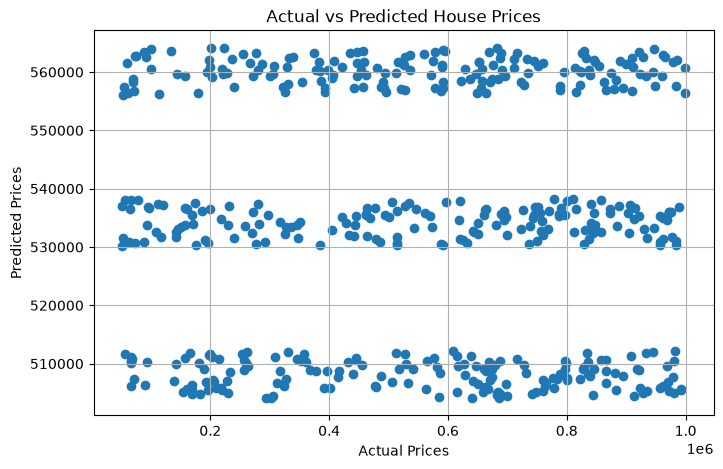

In [64]:
#Model Visualization
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")
plt.grid(True)

plt.savefig("Screenshot\\Task3_Actual_vs_Predicted.png",dpi=300, bbox_inches='tight')
plt.show()